# Análisis del comportamiento de una API REST bajo distintos escenarios de despliegue
**Curso:** Principios y prácticas de Desarrollo de Software Orientado a Objetos
**Autor:** _(completar)_  **Fecha:** _(completar)_

## 1. Introducción y objetivos
Se despliega la misma aplicación en: (a) Docker Compose en una sola máquina y (b) Kubernetes (K3s) con 1, 2 y 3 nodos, variando el número de réplicas (1, 2, 3). Con JMeter se genera carga con distintos números de usuarios concurrentes y se miden **tiempo medio de respuesta** y **throughput**. El objetivo es analizar el efecto del entorno, de las réplicas y de los nodos sobre la escalabilidad horizontal.

## 2. Descripción de la aplicación
API REST de catálogo de productos (FastAPI + PostgreSQL), código en `app/main.py`.

| Endpoint | Tipo | Descripción |
|---|---|---|
| `GET /products/{id}` | lectura | por clave primaria |
| `GET /products?category=&limit=` | lectura | lista filtrada (índice por categoría) |
| `GET /search?q=` | lectura | `ILIKE` sobre 20.000 filas (costosa) |
| `GET /stats` | lectura | agregación `GROUP BY` completa |
| `POST /products` | escritura | inserción |
| `PUT /products/{id}/stock` | escritura | actualización |

Base de datos: tabla `products` con **20.000 registros** (`db/init.sql`). Un solo worker de uvicorn por contenedor, de modo que el escalado se logra con réplicas.

## 3. Configuración de despliegue
- **Docker Compose:** `docker-compose.yml` (servicios `db` y `api`), en una máquina distinta a la de JMeter.
- **Kubernetes:** `k8s/*.yaml` (Namespace, Deployment+Service NodePort de la API, `topologySpreadConstraints` para repartir réplicas entre nodos y un Service `db` apuntando a la base de datos externa). **PostgreSQL corre en Docker en la VM A, fuera del clúster** (`docker-compose.db.yml`): al intentar ejecutarlo como pod en Ubuntu 26.04 (kernel 7.0), AppArmor bloqueaba las señales entre procesos de PostgreSQL y la base entraba en bucle de recuperación (manifiesto en `k8s/alternativa/`). Así, la base de datos queda fija en todos los escenarios y solo varían las réplicas y los nodos de la API. Recursos de la API fijos: requests 250m CPU / 128Mi, limits 500m CPU / 256Mi.
- **Clústeres:** K3s con 1, 2 y 3 nodos (`docs/CLUSTER_SETUP.md`). Réplicas con `kubectl scale deploy/api --replicas=N`.
- _(Completar: especificaciones de las máquinas — vCPU, RAM, proveedor, versión de K3s/Docker.)_

## 4. Metodología de carga con JMeter
- Plan `jmeter/plan.jmx`: cada usuario virtual ejecuta en bucle 6 peticiones (4 lecturas, 1 POST, 1 PUT) con IDs aleatorios.
- Niveles de carga: 10, 50, 100 y 200 usuarios concurrentes; ramp-up 10 s; duración 90 s por corrida; 3 repeticiones; 15 s de enfriamiento.
- JMeter en modo no-GUI (`jmeter/run_experiment.sh`) desde una máquina distinta a la del servidor.
- Se descartan los primeros 20 s de cada corrida (calentamiento y ramp-up) y se calculan: tiempo medio de respuesta (ms), percentil 95, throughput (req/s) y porcentaje de errores.

In [8]:
!unzip -q -o /content/results.zip -d /content/results
!ls /content/results | wc -l

96


In [9]:
import glob, os, re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
RESULTS_DIR = "/content/results"    # carpeta con los .jtl (en Colab: súbelos y ajusta la ruta)
WARMUP_S = 20                    # segundos a descartar al inicio de cada corrida

## 5. Carga y procesamiento de los resultados
Los archivos se llaman `<escenario>_n<nodos>_r<replicas>_t<hilos>_rep<k>.jtl`. Se calculan las métricas por corrida a partir de los datos crudos de JMeter.

In [10]:
pat = re.compile(r"(?P<scenario>[a-z0-9]+)_n(?P<nodes>\d+)_r(?P<replicas>\d+)_t(?P<threads>\d+)_rep(?P<rep>\d+)\.jtl$")

def summarize(path):
    m = pat.search(os.path.basename(path))
    if not m:
        return None
    df = pd.read_csv(path)
    t0 = df["timeStamp"].min()
    df = df[df["timeStamp"] >= t0 + WARMUP_S * 1000]
    if df.empty:
        return None
    ok = df["success"].astype(str).str.lower() == "true"
    dur_s = (df["timeStamp"].max() + df["elapsed"].iloc[-1] - df["timeStamp"].min()) / 1000
    d = m.groupdict()
    return {
        "scenario": d["scenario"], "nodes": int(d["nodes"]), "replicas": int(d["replicas"]),
        "threads": int(d["threads"]), "rep": int(d["rep"]),
        "samples": len(df),
        "avg_ms": df["elapsed"].mean(),
        "p95_ms": df["elapsed"].quantile(0.95),
        "throughput": len(df) / dur_s,
        "error_pct": 100 * (~ok).mean(),
    }

rows = [summarize(p) for p in sorted(glob.glob(f"{RESULTS_DIR}/*.jtl"))]
runs = pd.DataFrame([r for r in rows if r])
if runs.empty:
    print("No hay resultados en", RESULTS_DIR, "- ejecuta jmeter/run_experiment.sh primero.")
else:
    runs["config"] = runs.apply(lambda r: "Docker Compose" if r.scenario == "docker"
                                else f"K8s {r.nodes}n/{r.replicas}r", axis=1)
    display(runs.head())

,scenario,nodes,replicas,threads,rep,samples,avg_ms,p95_ms,throughput,error_pct,config
0,docker,1,1,100,1,5055,790.109001,1048.00,124.042992,0.0,Docker Compose
1,docker,1,1,100,2,4958,805.465309,1075.15,121.851115,0.0,Docker Compose
2,docker,1,1,10,1,4370,90.967277,133.00,109.499110,0.0,Docker Compose
3,docker,1,1,10,2,4358,91.259293,134.00,109.291536,0.0,Docker Compose
4,docker,1,1,30,1,4884,244.289312,398.85,121.759075,0.0,Docker Compose


In [11]:
summary = (runs.groupby(["config", "scenario", "nodes", "replicas", "threads"], as_index=False)
               .agg(avg_ms=("avg_ms", "mean"), avg_ms_std=("avg_ms", "std"),
                    p95_ms=("p95_ms", "mean"), throughput=("throughput", "mean"),
                    throughput_std=("throughput", "std"), error_pct=("error_pct", "mean"),
                    n_runs=("rep", "count")))
summary = summary.sort_values(["scenario", "nodes", "replicas", "threads"])
summary.round(2)

,config,scenario,nodes,replicas,threads,avg_ms,avg_ms_std,p95_ms,throughput,throughput_std,error_pct,n_runs
0,Docker Compose,docker,1,1,10,91.11,0.21,133.50,109.40,0.15,0.0,2
1,Docker Compose,docker,1,1,30,237.12,10.14,384.92,125.59,5.42,0.0,2
2,Docker Compose,docker,1,1,60,462.88,5.98,711.50,128.01,1.62,0.0,2
3,Docker Compose,docker,1,1,100,797.79,10.86,1061.57,122.95,1.55,0.0,2
4,K8s 1n/1r,k8s,1,1,10,75.82,8.20,198.50,131.93,14.07,0.0,2
5,K8s 1n/1r,k8s,1,1,30,294.54,9.86,485.12,101.05,3.64,0.0,2
6,K8s 1n/1r,k8s,1,1,60,524.32,7.45,824.67,112.52,1.12,0.0,2
7,K8s 1n/1r,k8s,1,1,100,886.72,10.01,1393.50,110.50,1.32,0.0,2
8,K8s 1n/2r,k8s,1,2,10,95.24,2.06,212.70,104.52,2.28,0.0,2
9,K8s 1n/2r,k8s,1,2,30,396.77,11.81,707.85,74.93,2.20,0.0,2


In [18]:
print("Archivos leídos:", len(runs))
print(runs.groupby("config").size())
print()
print("Error medio (%) por configuración:")
print(runs.groupby("config")["error_pct"].mean().round(2))

Archivos leídos: 80
config
Docker Compose    8
K8s 1n/1r         8
K8s 1n/2r         8
K8s 1n/3r         8
K8s 2n/1r         8
K8s 2n/2r         8
K8s 2n/3r         8
K8s 3n/1r         8
K8s 3n/2r         8
K8s 3n/3r         8
dtype: int64

Error medio (%) por configuración:
config
Docker Compose    0.0
K8s 1n/1r         0.0
K8s 1n/2r         0.0
K8s 1n/3r         0.0
K8s 2n/1r         0.0
K8s 2n/2r         0.0
K8s 2n/3r         0.0
K8s 3n/1r         0.0
K8s 3n/2r         0.0
K8s 3n/3r         0.0
Name: error_pct, dtype: float64


## 6. Resultados
### 6.1 Tiempo medio de respuesta y throughput por escenario

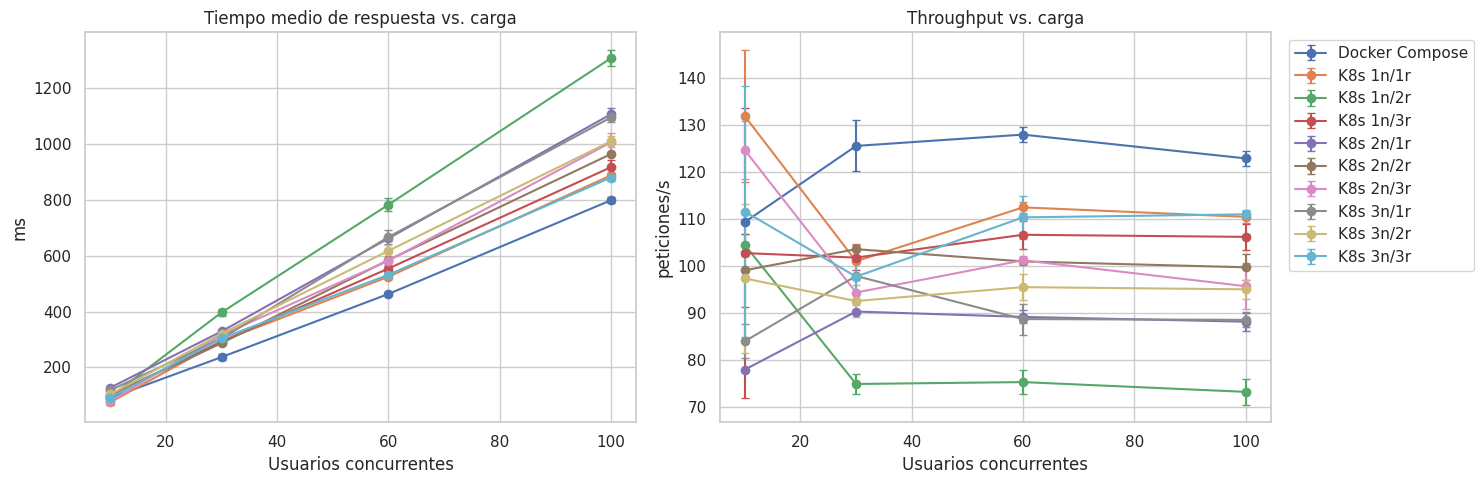

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for cfg, g in summary.groupby("config"):
    g = g.sort_values("threads")
    axes[0].errorbar(g["threads"], g["avg_ms"], yerr=g["avg_ms_std"].fillna(0), marker="o", capsize=3, label=cfg)
    axes[1].errorbar(g["threads"], g["throughput"], yerr=g["throughput_std"].fillna(0), marker="o", capsize=3, label=cfg)
axes[0].set(title="Tiempo medio de respuesta vs. carga", xlabel="Usuarios concurrentes", ylabel="ms")
axes[1].set(title="Throughput vs. carga", xlabel="Usuarios concurrentes", ylabel="peticiones/s")
axes[1].legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout(); plt.show()

In [13]:
print("Columnas:", summary.columns.tolist())
print("Escenarios:", summary.scenario.unique())
print("Filas de Kubernetes:", len(summary[summary.scenario != "docker"]))
print(runs.groupby("config").size())

Columnas: ['config', 'scenario', 'nodes', 'replicas', 'threads', 'avg_ms', 'avg_ms_std', 'p95_ms', 'throughput', 'throughput_std', 'error_pct', 'n_runs']
Escenarios: ['docker' 'k8s']
Filas de Kubernetes: 36
config
Docker Compose    8
K8s 1n/1r         8
K8s 1n/2r         8
K8s 1n/3r         8
K8s 2n/1r         8
K8s 2n/2r         8
K8s 2n/3r         8
K8s 3n/1r         8
K8s 3n/2r         8
K8s 3n/3r         8
dtype: int64


### 6.2 Efecto del número de réplicas (por número de nodos)

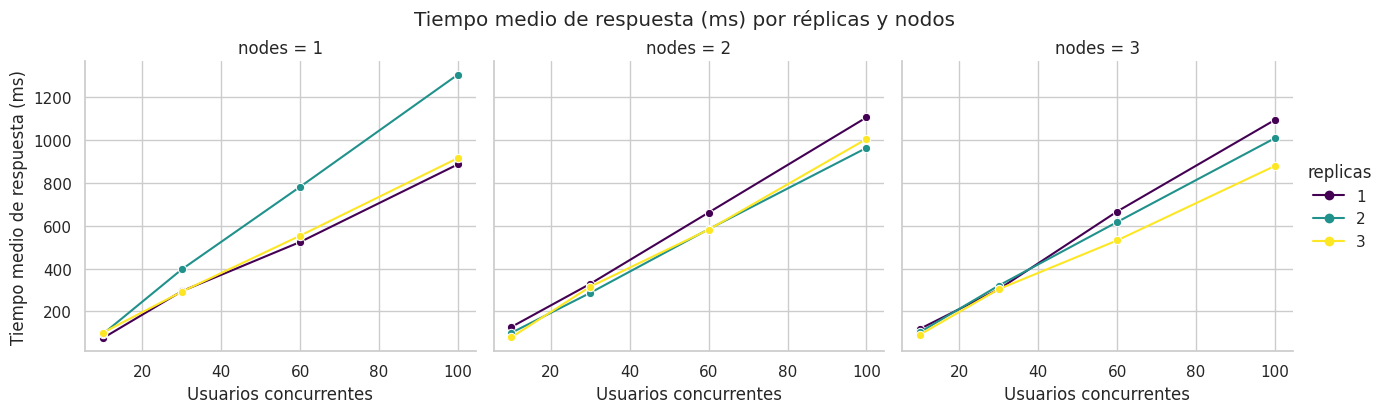

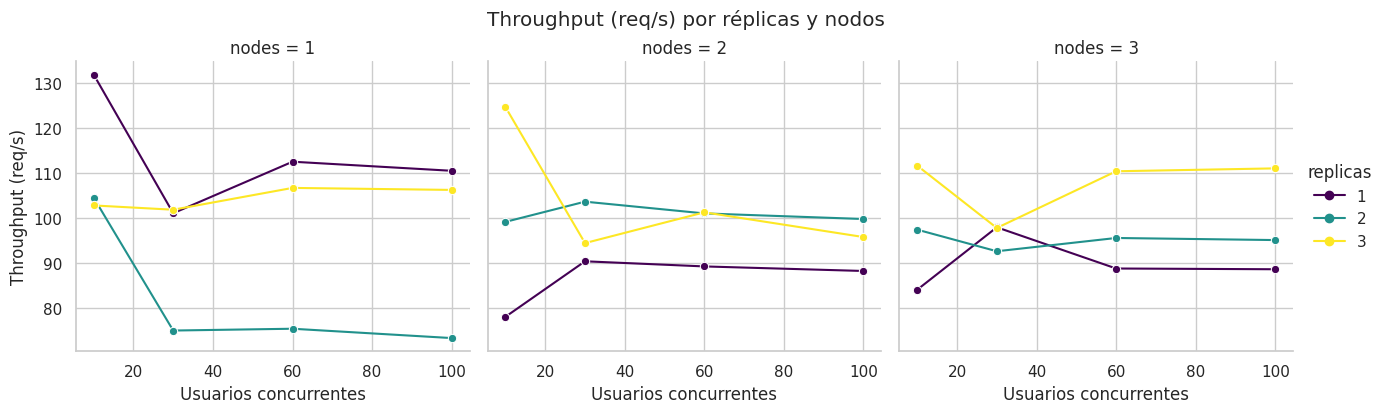

In [14]:
k8s = summary[summary.scenario != "docker"]
for metric, label in [("avg_ms", "Tiempo medio de respuesta (ms)"), ("throughput", "Throughput (req/s)")]:
    g = sns.relplot(data=k8s, x="threads", y=metric, hue="replicas", col="nodes", kind="line",
                    marker="o", palette="viridis", height=4, aspect=1.1)
    g.set_axis_labels("Usuarios concurrentes", label)
    g.figure.suptitle(label + " por réplicas y nodos", y=1.03)
    plt.show()

### 6.3 Mapas de calor (carga máxima y carga media)

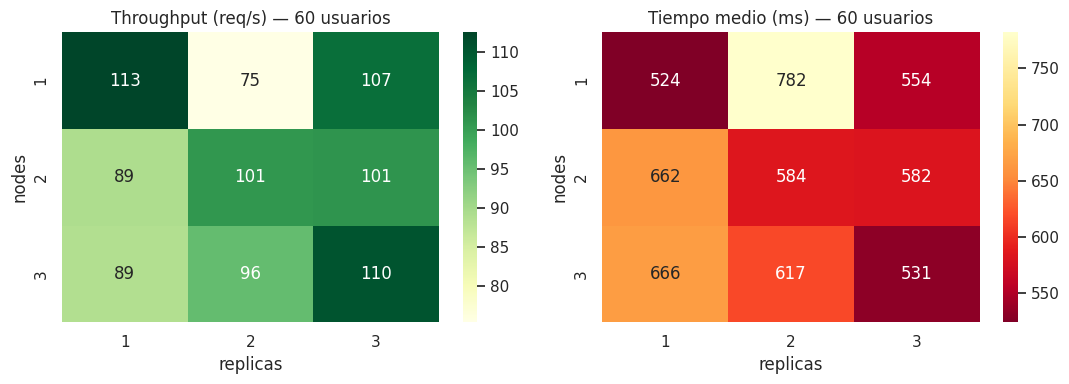

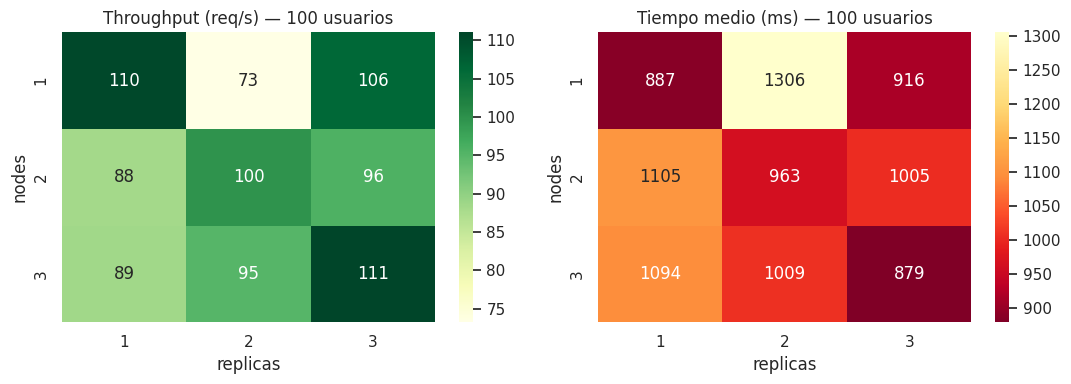

In [15]:
for th in sorted(k8s["threads"].unique())[-2:]:
    sub = k8s[k8s.threads == th]
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    sns.heatmap(sub.pivot(index="nodes", columns="replicas", values="throughput"), annot=True, fmt=".0f", cmap="YlGn", ax=axes[0])
    axes[0].set_title(f"Throughput (req/s) — {th} usuarios")
    sns.heatmap(sub.pivot(index="nodes", columns="replicas", values="avg_ms"), annot=True, fmt=".0f", cmap="YlOrRd_r", ax=axes[1])
    axes[1].set_title(f"Tiempo medio (ms) — {th} usuarios")
    plt.tight_layout(); plt.show()

### 6.4 Escalabilidad: speed-up del throughput respecto a 1 nodo / 1 réplica

,nodes,replicas,throughput,speedup,efficiency,error_pct
3,1,1,110.50,1.00,1.00,0.0
7,1,2,73.25,0.66,0.33,0.0
11,1,3,106.24,0.96,0.32,0.0
15,2,1,88.19,0.80,0.80,0.0
19,2,2,99.76,0.90,0.45,0.0
23,2,3,95.74,0.87,0.29,0.0
27,3,1,88.57,0.80,0.80,0.0
31,3,2,95.07,0.86,0.43,0.0
35,3,3,111.03,1.00,0.33,0.0


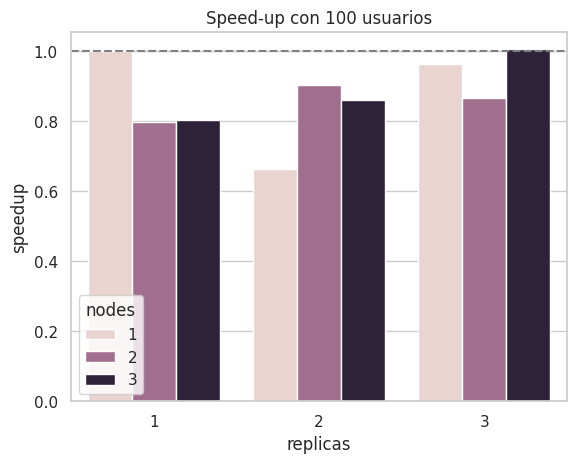

In [16]:
base = k8s[(k8s.nodes == 1) & (k8s.replicas == 1)][["threads", "throughput"]].rename(columns={"throughput": "base"})
sp = k8s.merge(base, on="threads")
sp["speedup"] = sp["throughput"] / sp["base"]
sp["efficiency"] = sp["speedup"] / sp["replicas"]
top = sp[sp.threads == sp.threads.max()]
display(top[["nodes", "replicas", "throughput", "speedup", "efficiency", "error_pct"]].round(2))
sns.barplot(data=top, x="replicas", y="speedup", hue="nodes")
plt.axhline(1, color="gray", ls="--"); plt.title(f"Speed-up con {sp.threads.max()} usuarios"); plt.show()

### 6.5 Tasa de errores

In [17]:
print(summary.pivot_table(index="config", columns="threads", values="error_pct").round(2))

threads         10   30   60   100
config                            
Docker Compose  0.0  0.0  0.0  0.0
K8s 1n/1r       0.0  0.0  0.0  0.0
K8s 1n/2r       0.0  0.0  0.0  0.0
K8s 1n/3r       0.0  0.0  0.0  0.0
K8s 2n/1r       0.0  0.0  0.0  0.0
K8s 2n/2r       0.0  0.0  0.0  0.0
K8s 2n/3r       0.0  0.0  0.0  0.0
K8s 3n/1r       0.0  0.0  0.0  0.0
K8s 3n/2r       0.0  0.0  0.0  0.0
K8s 3n/3r       0.0  0.0  0.0  0.0


## 7. (Opcional) Métricas internas con Prometheus/Grafana
_Si se usaron, describir aquí la instalación (p. ej. `helm install kube-prometheus-stack`) e incluir capturas o consultas de CPU/RAM por pod y por nodo para cada configuración._

## 8. Análisis comparativo
> **Completar con tus datos reales** una vez ejecutadas las pruebas. Preguntas guía:
> 1. ¿Cómo se comparan Docker Compose y K8s 1 nodo / 1 réplica? ¿Cuánto cuesta la capa de orquestación?
> 2. En 1 nodo, ¿mejora el throughput al pasar de 1 a 2 y 3 réplicas, o la CPU del nodo ya está saturada?
> 3. Al pasar a 2 y 3 nodos, ¿el speed-up se acerca al ideal? ¿Qué eficiencia (speed-up / réplicas) se obtiene?
> 4. ¿Dónde aparece el cuello de botella? Probablemente la base de datos (única instancia, `/search` y `/stats` son costosas) o el límite de CPU de los pods.
> 5. ¿A partir de qué carga aumentan los errores o el p95?
> 6. ¿Qué efecto tiene la latencia de red entre nodos hacia la base de datos?

## 9. Conclusiones
_(Completar con 4–6 conclusiones respaldadas por los números de las tablas y gráficos anteriores.)_

## 10. Recomendaciones
_(Ejemplos a evaluar según tus datos: escalar la BD o usar réplicas de lectura/caché, ajustar `resources` y `DB_POOL_MAX`, usar HPA, índices para `/search`, más nodos solo si la API es el cuello de botella.)_